<a href="https://colab.research.google.com/github/Hulusich28/YARAKSREpo/blob/main/curve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on CURVE

Acknowledgements: [Stefan Oehmcke](https://stefoe.github.io/) for the code used in this notebook.

This notebook will guide you through a data preprocessing pipeline implementing the CURVE framework you heard about in the lecture.

- CURVE: Clean – Unite – Record – Validate – Export
- Dataset: Our World in Data (OWID) CO2 + Energy (open, no API key)
- Question: Is a higher low-carbon electricity share associated with lower CO2 per capita (2000–2024)?

## Initial configuration

Import statements are in the first code cell, so the order in which later cells are executed only depends on what they are doing, not what packages they need (because all the packages are already loaded).

Also placing variables that configure high-level behaviour at the top of your notebooks makes it easier to repurpose a notebook.

In [ ]:
import pandas as pd
import numpy as np
from datetime import date
import platform
import matplotlib.pyplot as plt

YEARS = (2000, 2024)
MISSING_POLICY = "drop"         # options: "drop" | "interpolate"
INTERP_LIMIT = 2                # max consecutive years to fill when interpolating
EXPORT_BASENAME = f"owid_co2_energy_ready_{date.today().isoformat()}"

CO2_URL    = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
ENERGY_URL = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"

## Load data

:::{important} Tasks
1. Use [pandas.read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) to load each of the datasets.
:::

In [ ]:
import pandas
CO2_URL    = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"

co2_raw = pandas.read_csv(CO2_URL)  # TODO
co2_raw

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.000,0.000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50406,Zimbabwe,2020,ZWE,15526887.0,2.317871e+10,0.496,0.032,8.491,-1.776,-17.298,...,NaN,0.106,0.001,0.001,0.002,0.0,24.146,14.463,1.991,23.450
50407,Zimbabwe,2021,ZWE,15797220.0,2.514009e+10,0.542,0.034,10.223,1.732,20.398,...,NaN,0.105,0.001,0.001,0.002,0.0,27.907,16.408,2.137,20.899
50408,Zimbabwe,2022,ZWE,16069061.0,2.590159e+10,0.387,0.024,12.232,2.009,19.653,...,NaN,0.104,0.001,0.001,0.002,0.0,29.917,18.830,1.380,11.283
50409,Zimbabwe,2023,ZWE,16340829.0,NaN,0.387,0.024,13.443,1.211,9.904,...,NaN,0.103,0.001,0.001,0.002,0.0,31.029,20.318,1.876,13.957


In [ ]:
import pandas
ENERGY_URL = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"

energy_raw = pandas.read_csv(ENERGY_URL) # TODO
energy_raw

,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23372,Zimbabwe,2020,ZWE,15526887.0,2.317871e+10,NaN,0.0,0.0,0.0,6.440,...,0.298,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23373,Zimbabwe,2021,ZWE,15797220.0,2.514009e+10,NaN,0.0,0.0,0.0,6.963,...,0.233,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23374,Zimbabwe,2022,ZWE,16069061.0,2.590159e+10,NaN,0.0,0.0,0.0,6.845,...,0.336,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23375,Zimbabwe,2023,ZWE,16340829.0,NaN,NaN,0.0,0.0,0.0,7.344,...,0.300,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN


# C = Clean

## Select only necessary columns

We don't need all of the many columns that are available.
This selects only a necessary subset of columns.

In [ ]:
co2_keep = ["iso_code", "country", "year", "co2_per_capita"]
co2 = co2_raw[co2_keep].copy()
co2

,iso_code,country,year,co2_per_capita
0,AFG,Afghanistan,1750,NaN
1,AFG,Afghanistan,1751,NaN
2,AFG,Afghanistan,1752,NaN
3,AFG,Afghanistan,1753,NaN
4,AFG,Afghanistan,1754,NaN
...,...,...,...,...
50406,ZWE,Zimbabwe,2020,0.547
50407,ZWE,Zimbabwe,2021,0.647
50408,ZWE,Zimbabwe,2022,0.761
50409,ZWE,Zimbabwe,2023,0.823


In [ ]:
# Prefer low_carbon_electricity_share; fall back to renewables_share_elec if needed
cands = [c for c in energy_raw.columns if "low_carbon_electricity_share" in c] \
        or [c for c in energy_raw.columns if "renewables_share_elec" in c]
share_col = cands[0]

energy_keep = ["iso_code", "country", "year", share_col, "electricity_demand", "population", "gdp"]
energy = energy_raw[energy_keep].copy()
energy = energy.rename(columns={share_col: "low_carbon_elec_share"})  # whatever share column we end up using, give it a fixed name
energy_keep = ["iso_code", "country", "year", "low_carbon_elec_share", "electricity_demand", "population", "gdp"]
energy

,iso_code,country,year,low_carbon_elec_share,electricity_demand,population,gdp
0,NaN,ASEAN (Ember),2000,6.020,378.76,NaN,NaN
1,NaN,ASEAN (Ember),2001,5.643,405.09,NaN,NaN
2,NaN,ASEAN (Ember),2002,5.363,433.19,NaN,NaN
3,NaN,ASEAN (Ember),2003,5.058,458.30,NaN,NaN
4,NaN,ASEAN (Ember),2004,5.026,496.61,NaN,NaN
...,...,...,...,...,...,...,...
23372,ZWE,Zimbabwe,2020,1.490,8.69,15526887.0,2.317871e+10
23373,ZWE,Zimbabwe,2021,1.284,10.31,15797220.0,2.514009e+10
23374,ZWE,Zimbabwe,2022,1.230,10.85,16069061.0,2.590159e+10
23375,ZWE,Zimbabwe,2023,1.201,11.99,16340829.0,NaN


:::{tip} Your answer
:class:dropdown
2.


Yes it´s tidy because each variable forms a column. Furthermore each observation forms a row and each value is a cell and no cell contains multiple values
:::

## Handle missing data

First have a look at where data is missing.
We do this by printing which columns include missing values.

In [ ]:
for col in co2_keep:
    has_na = co2[col].notna().all()
    print(f"{col}: {'some missing' if has_na else 'complete'}")

iso_code: complete
country: some missing
year: some missing
co2_per_capita: complete


In [ ]:
for col in energy_keep:
    has_na = energy[col].notna().all()
    print(f"{col}: {'some missing' if has_na else 'complete'}")

iso_code: complete
country: some missing
year: some missing
low_carbon_elec_share: complete
electricity_demand: complete
population: complete
gdp: complete


:::{important} Tasks
3. Implement the case in which missing data should be dropped.
:::

In [ ]:
def handle_missing(data, req_cols):
    # Missing data policy: DROP vs INTERPOLATE
    if MISSING_POLICY == "drop":
       data= data.dropna(subset=req_cols)

    elif MISSING_POLICY == "interpolate":
        # Interpolate within each country over time (linear), up to INTERP_LIMIT consecutive years
        data = data.sort_values(["iso_code", "year"])

        def _interp_country(g):
            g = g.copy()
            for c in req_cols:
                g[c] = g[c].interpolate(method="linear", limit=INTERP_LIMIT, limit_direction="both")
                # optional: clamp to valid share range after interpolation
                if c == "low_carbon_elec_share":
                    g["low_carbon_elec_share"] = g["low_carbon_elec_share"].clip(lower=0, upper=100)
            return g

        na_before = data[req_cols].isna().sum().sum()
        data = data.groupby("iso_code", group_keys=False).apply(_interp_country)
        na_after = data[req_cols].isna().sum().sum()
        print(f"[Missing policy: INTERPOLATE] NA cells before: {na_before}  after: {na_after}")

        # If some NAs remain (long gaps), drop them so validation is simple for students.
        if na_after > 0:
            rows_before = len(data)
            data = data.dropna(subset=req_cols)
            print(f"Remaining NA rows removed after interpolation: {rows_before - len(data)}")

        print("Comment: OK for short, smooth gaps; document the assumption. Avoid long-gap fills or extrapolation.")
    else:
        raise ValueError("MISSING_POLICY must be 'drop' or 'interpolate'.")

    return data

In [ ]:
# cannot interpolate -> drop
co2 = co2.dropna(subset=["iso_code"])
energy = energy.dropna(subset=["iso_code"])

# interpolate if requested
co2 = handle_missing(co2, ["co2_per_capita"])
energy = handle_missing(energy, ["low_carbon_elec_share"])

:::{important} Tasks
We only need data for the specified time range, that was configured in the very first code cell of this notebook.

4. Select rows in both `co2` and `energy` based on `YEARS`.
:::

In [ ]:
co2 = co2.query("2000<= year <= 2024")  # TODO: add the query
energy = energy.query("2000<= year <= 2024")  # TODO: add the query

In [ ]:
print(f"#co2 records: {len(co2)}")  # should be 5325
print(f"#energy records: {len(energy)}")  # should be 5243

#co2 records: 5325
#energy records: 5243


## Inspecting the data

In [ ]:
co2.describe()

,year,co2_per_capita
count,5014.000000,4899.00000
mean,2012.000000,5.04644
std,6.633911,6.49587
min,2001.000000,0.02100
25%,2006.000000,0.80300
50%,2012.000000,2.86700
75%,2018.000000,6.80750
max,2023.000000,67.72700


In [ ]:
energy.describe()

,year,low_carbon_elec_share,electricity_demand,population,gdp
count,5243.000000,5243.000000,5243.000000,5.243000e+03,3.774000e+03
mean,2012.010299,2.772051,107.143910,3.422386e+07,5.719333e+11
std,7.180661,7.130797,505.747035,1.332922e+08,1.925700e+12
min,2000.000000,0.000000,0.010000,3.119000e+03,3.128536e+08
25%,2006.000000,0.000000,0.930000,9.479885e+05,2.353973e+10
50%,2012.000000,0.045000,7.740000,6.346993e+06,7.815410e+10
75%,2018.000000,1.737500,44.895000,2.289637e+07,3.535943e+11
max,2024.000000,77.586000,10069.880000,1.450936e+09,2.696602e+13


:::{important} Tasks
5. Does this indicate that the correct range of years was selected?
Yes the min and max value shows that the values begin at 2000 and end in 2024


6. Is the data roughly equally distributed across the years? (Based on percentiles)
:::

yes because with the percentile you can see that 25 percent of the values are in the area of 2006, then 50 percent are in 2012 and then 75 percent are in 75%

:::{tip} Your answer
:class:dropdown
5.
6.
:::

# U = UNITE

:::{important} Tasks
We want to combine the `co2` and `energy` dataframes by finding matching rows (based on the `iso_code` **and** `year` columns) and merging each match into a new row, creating a new dataframe.

7. Implement this operation using the [pandas.DataFrame.merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html) method and assign it to a new variable called `df`.

Read into the documentation of the `how` parameter to find out which kind of merge operation you need here.
:::

In [ ]:
df = co2.merge(energy, on=['iso_code', 'year'])

In [ ]:
print(f"#merged records: {len(df)}")  # should be 4976

#merged records: 4976


# R = RECORD

:::{important} Tasks
8. What are the data sources?

Dataset from the URL

9. What major decisions on how to handle the data have been taken?
    1. Was any data removed?
        Yes rows with missing columns were removed
    2. Were data types changed?
        no
    3. Were columns/rows/cells merged or split?
      unnecessary columns were erased
      The Dataset from energy and co2 was merged with the matching years and iso_codes
    4. Were identifiers of columns/rows changed?
      no

A systematic and extended version of this was published in the [ODE protocol](https://www.sciencedirect.com/science/article/pii/S1364815226000599) (Table 1).
:::

:::{tip} Your answer
:class:dropdown
8.
9.
    1.
    2.
    3.
    4.
:::

# V = VALIDATE

## Check essential properties

:::{important} Tasks
10. Implement an assertion, that checks that there are no repeated ISO codes or years.
11. Implement an assertion, that checks that all values in `low_carbon_elec_share` are within the interval [0,100].
:::

In [ ]:
# 1) Keys unique per (iso_code, year)
pass

# 2) Required fields not NA
assert ~df[req_cols].isna().any().any(), "Missing values remain in required columns."

# 3) Value ranges
assert (df["co2_per_capita"] >= 0).all(), "Negative CO2 per capita values detected."
# TODO

# 4) Optional plausibility cap (very high extremes rarely occur)
assert df.loc[(df["co2_per_capita"] > 80) | (df["low_carbon_elec_share"] > 100)].empty, "Implausible extremes present."

print("Validation passed ✅")

NameError: name 'req_cols' is not defined

## Quick sanity outputs

Countries: 201 | Rows: 4976 | Years: [2000–2024]
Pearson corr(co2_per_capita, low_carbon_elec_share) = -0.068


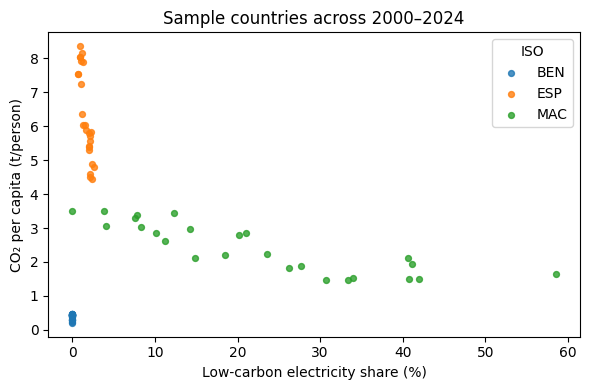

In [ ]:
n_countries = df["iso_code"].nunique()
n_rows = len(df)
print(f"Countries: {n_countries} | Rows: {n_rows} | Years: [{df['year'].min()}–{df['year'].max()}]")

# Simple correlation
corr = df[["co2_per_capita", "low_carbon_elec_share"]].corr().iloc[0,1]
print(f"Pearson corr(co2_per_capita, low_carbon_elec_share) = {corr:.3f}")

# Tiny scatter for a feel (random 3 countries)
sample_c = df["iso_code"].drop_duplicates().sample(n=min(3, n_countries), random_state=0).tolist()
sub = df[df["iso_code"].isin(sample_c)]
plt.figure(figsize=(6,4))
for c in sample_c:
    cc = sub[sub["iso_code"]==c]
    plt.scatter(cc["low_carbon_elec_share"], cc["co2_per_capita"], label=c, s=18, alpha=0.8)
plt.xlabel("Low-carbon electricity share (%)")
plt.ylabel("CO₂ per capita (t/person)")
plt.title("Sample countries across 2000–2024")
plt.legend(title="ISO")
plt.tight_layout()
plt.show()

# E = EXPORT

:::{important} Tasks
12. Save the contents of `df` in CSV format without the index using [pandas.DataFrame.to_csv](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html).
:::

In [ ]:
df.to_csv(index=False)

"iso_code,country_x,year,co2_per_capita,country_y,low_carbon_elec_share,electricity_demand,population,gdp\nAFG,Afghanistan,2000,0.052,Afghanistan,0.0,0.57,20130334.0,11283794151.0\nAFG,Afghanistan,2001,0.053,Afghanistan,0.0,0.78,20284303.0,11021272927.0\nAFG,Afghanistan,2002,0.063,Afghanistan,0.0,0.81,21378123.0,18804871508.0\nAFG,Afghanistan,2003,0.069,Afghanistan,0.0,1.01,22733053.0,21074343420.0\nAFG,Afghanistan,2004,0.053,Afghanistan,0.0,0.89,23560656.0,22332570533.0\nAFG,Afghanistan,2005,0.077,Afghanistan,0.0,0.92,24404575.0,25397686814.0\nAFG,Afghanistan,2006,0.085,Afghanistan,0.0,1.33,25424100.0,28704399925.0\nAFG,Afghanistan,2007,0.108,Afghanistan,0.0,1.62,25909852.0,34507529735.0\nAFG,Afghanistan,2008,0.161,Afghanistan,0.0,1.53,26482631.0,36561043230.0\nAFG,Afghanistan,2009,0.233,Afghanistan,0.0,2.04,27466102.0,44358722212.0\nAFG,Afghanistan,2010,0.296,Afghanistan,0.0,2.75,28284088.0,47399425562.0\nAFG,Afghanistan,2011,0.389,Afghanistan,0.0,3.5,29347708.0,53326336000.0\nAFG,Af

## Reproduction notes

:::{important} Tasks
13. Print version information for your installation of Python as well as used packages.
14. Print configuration values.
15. Print column names, that you saved in the previous step.
:::

In [ ]:
import pandas

pandas.show_versions()


INSTALLED VERSIONS
------------------
commit                : 0691c5cf90477d3503834d983f69350f250a6ff7
python                : 3.13.16
python-bits           : 64
OS                    : Linux
OS-release            : 6.6.122+
Version               : #1 SMP Thu Apr 30 18:17:14 UTC 2026
machine               : x86_64
processor             : x86_64
byteorder             : little
LC_ALL                : en_US.UTF-8
LANG                  : en_US.UTF-8
LOCALE                : en_US.UTF-8

pandas                : 2.2.3
numpy                 : 2.1.3
pytz                  : 2025.2
dateutil              : 2.9.0.post0
pip                   : 24.1.2
Cython                : 3.0.12
sphinx                : 8.2.3
IPython               : 7.34.0
adbc-driver-postgresql: None
adbc-driver-sqlite    : None
bs4                   : 4.13.5
blosc                 : None
bottleneck            : 1.4.2
dataframe-api-compat  : None
fastparquet           : None
fsspec                : 2025.12.0
html5lib              

:::{important} Tasks
Check out the [pyproject.toml](https://github.com/bckrlab/data-science-course/blob/main/pyproject.toml) file in the underlying git repository.

16. How much of this printout is already defined there?
17. Research/Discuss: Why is it better to have a file like pyproject.toml compared to the printouts?
::: It´s in a more structured instance and thus better to understand and analyze for a machine whereas the printout is primarily for the human to understand

:::{tip} Your answer
:class:dropdown
16.
17.
:::